4C8 Tổng số ngày dữ liệu: 180 

Train: 166 ngày | Test (14 ngày cuối): 14 ngày


 ARIMA(0,0,0)           with zero mean     : 1808.702
 ARIMA(0,0,0)           with non-zero mean : 1131.673
 ARIMA(0,0,0)(0,0,1)[7] with zero mean     : 1637.287
 ARIMA(0,0,0)(0,0,1)[7] with non-zero mean : 1133.715
 ARIMA(0,0,0)(0,0,2)[7] with zero mean     : 1532.378
 ARIMA(0,0,0)(0,0,2)[7] with non-zero mean : 1134.62
 ARIMA(0,0,0)(1,0,0)[7] with zero mean     : Inf
 ARIMA(0,0,0)(1,0,0)[7] with non-zero mean : 1133.721
 ARIMA(0,0,0)(1,0,1)[7] with zero mean     : Inf
 ARIMA(0,0,0)(1,0,1)[7] with non-zero mean : 1134.816
 ARIMA(0,0,0)(1,0,2)[7] with zero mean     : Inf
 ARIMA(0,0,0)(1,0,2)[7] with non-zero mean : 1136.49
 ARIMA(0,0,0)(2,0,0)[7] with zero mean     : Inf
 ARIMA(0,0,0)(2,0,0)[7] with non-zero mean : 1134.711
 ARIMA(0,0,0)(2,0,1)[7] with zero mean     : Inf
 ARIMA(0,0,0)(2,0,1)[7] with non-zero mean : 1136.466
 ARIMA(0,0,0)(2,0,2)[7] with zero mean     : Inf
 ARIMA(0,0,0)(2,0,2)[7] with non

Series: ts_train 
ARIMA(0,0,0) with non-zero mean 

Coefficients:
         mean
      55.3916
s.e.   0.5607

sigma^2 = 52.51:  log likelihood = -563.8
AIC=1131.6   AICc=1131.67   BIC=1137.82

Training set error measures:
                       ME     RMSE      MAE       MPE     MAPE      MASE
Training set 1.520134e-12 7.224268 5.615256 -1.762974 10.44266 0.6997067
                   ACF1
Training set 0.04720968


=> Mô hình được chọn chính xác là: SARIMA(0,0,0) x (0,0,0)[7]

===== ĐÁNH GIÁ ĐỘ CHÍNH XÁC TRÊN TẬP TEST (14 NGÀY) =====
MAE  : 6.5310
RMSE : 7.6799
MAPE : 11.3918%



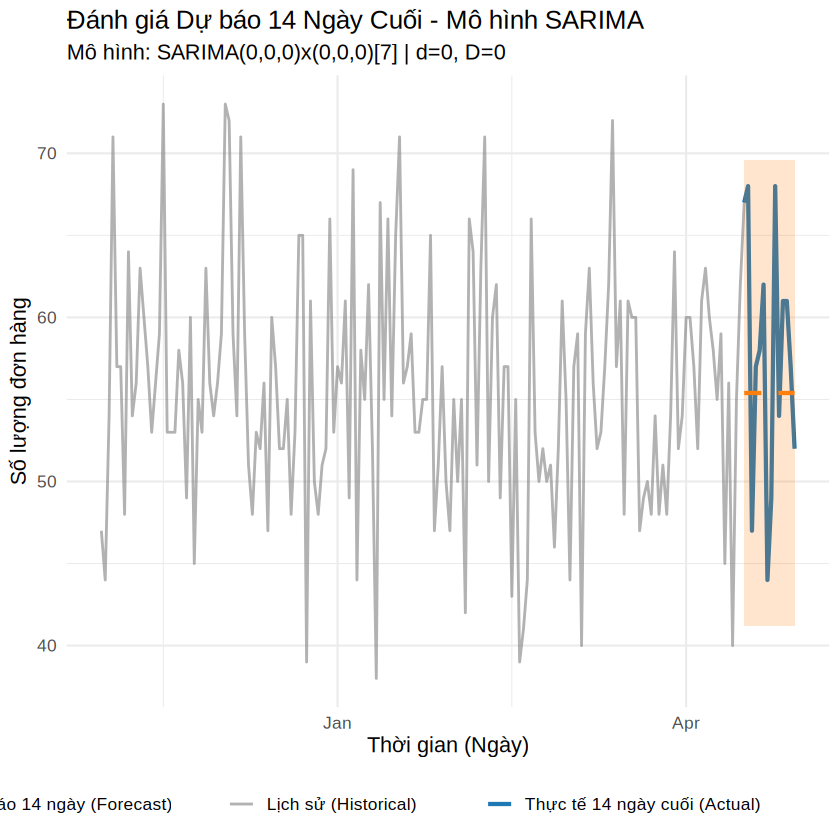

In [13]:
# ============================================================
# PHÂN TÍCH & DỰ BÁO SARIMA (với d=0, D=0 và Kiểm thử 14 ngày cuối)
# ============================================================

# 1. Cài đặt và tải các thư viện cần thiết
pkgs <- c("forecast", "tseries", "ggplot2", "dplyr", "tidyr", "lubridate")
for (p_pkg in pkgs) {
  if (!require(p_pkg, character.only = TRUE)) {
    install.packages(p_pkg, repos = "https://cloud.r-project.org", quiet = TRUE)
  }
  library(p_pkg, character.only = TRUE)
}

# 2. Đọc và xử lý dữ liệu
df <- read.csv("cleaned_data (1).csv")

# Chuyển đổi cột thời gian và tổng hợp số lượng đơn hàng theo ngày
df$order_time <- ymd_hms(df$order_time)
df$date <- as.Date(df$order_time)

daily_orders <- df %>%
  group_by(date) %>%
  summarise(orders = n()) %>%
  complete(date = seq.Date(min(date), max(date), by="day"), fill = list(orders = 0))

# Chuyển đổi thành đối tượng chuỗi thời gian (Time Series) với chu kỳ mùa vụ theo tuần (frequency = 7)
ts_orders <- ts(daily_orders$orders, frequency = 7)

cat("4C8 Tổng số ngày dữ liệu:", length(ts_orders), "\n\n")

# ============================================================
# 3. CHIA TẬP TRAIN / TEST (14 NGÀY CUỐI ĐỂ ĐÁNH GIÁ)
# ============================================================
H_TEST  <- 14
n       <- length(ts_orders)
n_train <- n - H_TEST

# Cắt chuỗi thành tập Train và Test
ts_train <- window(ts_orders, end = time(ts_orders)[n_train])
ts_test  <- window(ts_orders, start = time(ts_orders)[n_train + 1])

cat(sprintf("Train: %d ngày | Test (14 ngày cuối): %d ngày\n\n", length(ts_train), length(ts_test)))

# ============================================================
# 4. TÌM MÔ HÌNH SARIMA TỐI ƯU TRÊN TẬP TRAIN (d = 0, D = 0)
# ============================================================
best_sarima <- auto.arima(ts_train,
                          seasonal = TRUE,
                          d = 0,             # Cố định sai phân không mùa vụ d = 0
                          D = 0,             # Cố định sai phân mùa vụ D = 0
                          stepwise = FALSE,
                          approximation = FALSE,
                          trace = TRUE)

# --- IN KẾT QUẢ MÔ HÌNH TỐI ƯU ---
cat("\n========================================\n")
cat(" KẾT QUẢ MÔ HÌNH TỐI ƯU: SARIMA\n")
cat("========================================\n")
summary(best_sarima)

# Trích xuất các bậc tham số (p,d,q) và (P,D,Q)[m]
p <- best_sarima$arma[1]
d <- best_sarima$arma[6]
q <- best_sarima$arma[2]
P <- best_sarima$arma[3]
D <- best_sarima$arma[7]
Q <- best_sarima$arma[4]
m <- best_sarima$arma[5]

cat(sprintf("\n=> Mô hình được chọn chính xác là: SARIMA(%d,%d,%d) x (%d,%d,%d)[%d]\n", p, d, q, P, D, Q, m))
cat("========================================\n\n")

# ============================================================
# 5. DỰ BÁO TRÊN TẬP TEST (14 NGÀY) VÀ ĐÁNH GIÁ ĐỘ CHÍNH XÁC
# ============================================================
fc_test <- forecast(best_sarima, h = H_TEST, level = c(80, 95))

# Tính toán thủ công các chỉ số đánh giá để tránh lỗi thuộc tính của lớp ts
actual_vals <- as.numeric(ts_test)
pred_vals   <- as.numeric(fc_test$mean)

mae_val  <- mean(abs(actual_vals - pred_vals))
rmse_val <- sqrt(mean((actual_vals - pred_vals)^2))
mape_val <- mean(abs((actual_vals - pred_vals) / actual_vals)) * 100

cat("===== ĐÁNH GIÁ ĐỘ CHÍNH XÁC TRÊN TẬP TEST (14 NGÀY) =====\n")
cat(sprintf("MAE  : %.4f\n", mae_val))
cat(sprintf("RMSE : %.4f\n", rmse_val))
cat(sprintf("MAPE : %.4f%%\n\n", mape_val))

# Xuất kết quả đánh giá ra file CSV
eval_result <- data.frame(
  Model = sprintf("SARIMA(%d,%d,%d)x(%d,%d,%d)[%d]", p, d, q, P, D, Q, m),
  MAE   = mae_val,
  RMSE  = rmse_val,
  MAPE  = mape_val
)
write.csv(eval_result, "sarima_test_evaluation.csv", row.names = FALSE)

# ============================================================
# 6. TRỰC QUAN HÓA KẾT QUẢ DỰ BÁO 14 NGÀY CUỐI
# ============================================================
# Chuẩn bị dữ liệu vẽ biểu đồ cho tập Test và Dự báo
test_dates <- tail(daily_orders$date, H_TEST)

df_plot <- data.frame(
  Date      = rep(test_dates, 2),
  Orders    = c(actual_vals, pred_vals),
  Type      = c(rep("Thực tế (Actual)", H_TEST), rep("Dự báo (Forecast)", H_TEST)),
  Lower95   = c(rep(NA, H_TEST), as.numeric(fc_test$lower[, 2])),
  Upper95   = c(rep(NA, H_TEST), as.numeric(fc_test$upper[, 2]))
)

p_plot <- ggplot() +
  # Vẽ đường lịch sử tổng thể hoặc phóng to 14 ngày cuối so sánh
  geom_line(data = data.frame(Date = daily_orders$date, Value = daily_orders$orders),
            aes(x = Date, y = Value, color = "Lịch sử (Historical)"), linewidth = 0.8, alpha = 0.6) +
  geom_line(data = data.frame(Date = test_dates, Value = actual_vals),
            aes(x = Date, y = Value, color = "Thực tế 14 ngày cuối (Actual)"), linewidth = 1.2) +
  geom_line(data = data.frame(Date = test_dates, Value = pred_vals),
            aes(x = Date, y = Value, color = "Dự báo 14 ngày (Forecast)"), linewidth = 1.2, linetype = "dashed") +
  geom_ribbon(data = df_plot[!is.na(df_plot$Lower95), ],
              aes(x = Date, ymin = Lower95, ymax = Upper95, fill = "Khoảng tin cậy 95%"), alpha = 0.2) +
  scale_color_manual(values = c(
    "Lịch sử (Historical)" = "#7f7f7f",
    "Thực tế 14 ngày cuối (Actual)" = "#1f77b4",
    "Dự báo 14 ngày (Forecast)" = "#ff7f0e"
  )) +
  scale_fill_manual(values = c("Khoảng tin cậy 95%" = "#ff7f0e")) +
  labs(
    title = "Đánh giá Dự báo 14 Ngày Cuối - Mô hình SARIMA",
    subtitle = sprintf("Mô hình: SARIMA(%d,%d,%d)x(%d,%d,%d)[%d] | d=0, D=0", p, d, q, P, D, Q, m),
    x = "Thời gian (Ngày)",
    y = "Số lượng đơn hàng",
    color = "Chú thích",
    fill = ""
  ) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

# Hiển thị biểu đồ
print(p_plot)